# Body fat: concurved girth measurements

Waist and hip circumference measure overlapping aspects of the same body.
A model that offers a smooth term for each must divide their shared
information between two curves, and the division is not determined by the
data. This page fits such a model, quantifies the overlap with `concurvity`, and
tests what the overlap means for prediction and for reading the effects.

This case introduces `concurvity` in a specification decision. It assumes
the workflow of [](bodyfat.ipynb): a `gamboost` fit tuned by `cvrisk` and
read through partial effects. The main analysis ends with a prediction
table and the decision the diagnostic supports; the extensions examine
whether the split between two concurved terms is stable across samples,
and what a basis too rich for the sample does to the worst-case measure.

## The data

The `bodyfat` data contain 71 women from the study used in the mboost
tutorial {cite}`hofner2014mboost_tutorial`. The response, `DEXfat`, is
body fat in kg measured by dual-energy X-ray absorptiometry (DEXA). Four predictors are used: age in
years, waist and hip circumference in cm — two girth measurements of the
same body — and `anthro3c`, a derived anthropometric index. A row
describes one woman; the women are treated as independent observations.


In [1]:
import altair as alt
import numpy as np
import polars as pl
from IPython.display import display

import mboostrs as mb

data = mb.datasets.bodyfat(output="polars")
n = data.height
display(data.select("DEXfat", "age", "waistcirc", "hipcirc", "anthro3c").head())


DEXfat,age,waistcirc,hipcirc,anthro3c
f64,i64,f64,f64,f64
41.68,57,100.0,112.0,4.5
43.29,65,99.5,116.5,4.48
35.41,59,96.0,108.5,4.6
22.79,58,72.0,96.5,3.91
36.42,60,89.5,100.5,4.15


## A smooth model: four terms

`gamboost` fits an additive predictor: a constant offset plus one
contribution per term, and at each boosting step the algorithm adds a
fraction `nu` of one term's least-squares update; `cvrisk` chooses how many
updates to keep. The mechanism is introduced in [](bodyfat.ipynb).

`knots=8` sets the number of knots (the points where the pieces of a spline join) in each basis, which holds each basis near twelve columns. Four default `bbs`
bases would hold about 24 columns each, and 96 columns for 71 women would
let the four term spaces fill the whole observation space, a saturation the
concurvity diagnostic reports and the second extension demonstrates.
`mstop=400` is the number of updates made available; `nu=0.1` is the
fraction of each update that enters the fit. `Gaussian()` loss makes every
prediction below an estimate of mean DEXA fat in kg.


Selected 35 of 400 updates; ten-fold RMSE 3.91 kg.


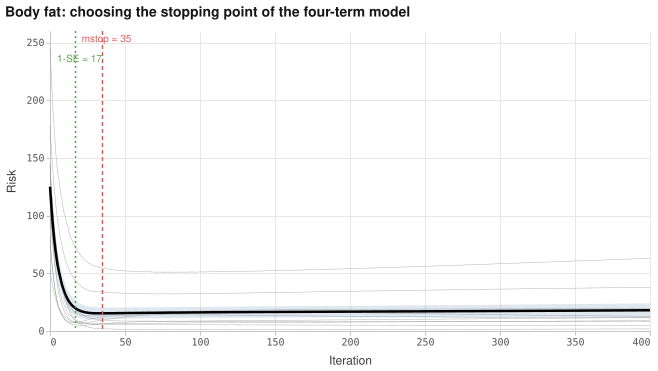

In [2]:
folds = mb.cv_weights(n, type="kfold", B=10, seed=1)
formula = (
    "DEXfat ~ bbs(age, knots=8) + bbs(waistcirc, knots=8)"
    " + bbs(hipcirc, knots=8) + bbs(anthro3c, knots=8)"
)
path = mb.gamboost(
    formula, data=data, family=mb.Gaussian(),
    control=mb.boost_control(mstop=400, nu=0.1),
)
cv = path.cvrisk(folds=folds)
fit = path[:cv.optimal_mstop]
rmse = float(np.sqrt(np.min(cv.aggregate)))

# How many of the chosen updates each term received; used when reading the
# partial effects below.
fit_updates = {r["learner"]: r["updates"]
               for r in fit.selection_counts(output="records")}
print(f"Selected {cv.optimal_mstop} of 400 updates; ten-fold RMSE {rmse:.2f} kg.")
mb.plot.plot_cvrisk(cv).properties(
    title="Body fat: choosing the stopping point of the four-term model",
)


The curve selects {eval}`cv.optimal_mstop` updates, and the ten-fold root
mean squared error is {eval}`f"{rmse:.2f}"` kg. The tuned model carries all
four terms: hip circumference received {eval}`fit_updates["hipcirc"]`
updates, the derived index {eval}`fit_updates["anthro3c"]`, waist
circumference {eval}`fit_updates["waistcirc"]` and age
{eval}`fit_updates["age"]`.

## Partial effects of two girth measurements

A partial effect is one term's contribution to the additive prediction.
For a girth measurement it is a curve in kg against circumference in cm,
conditional on the other terms. The plots below show the two fitted
contributions on the training rows.


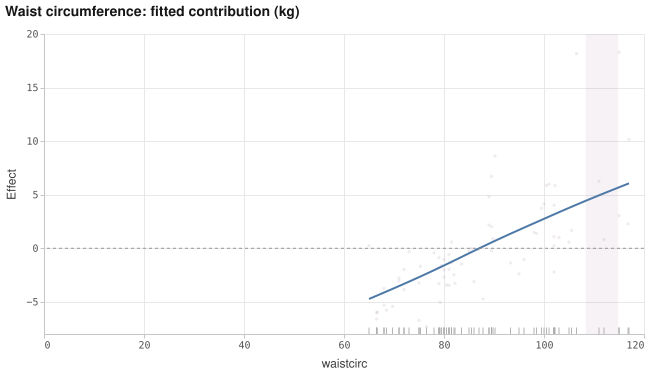

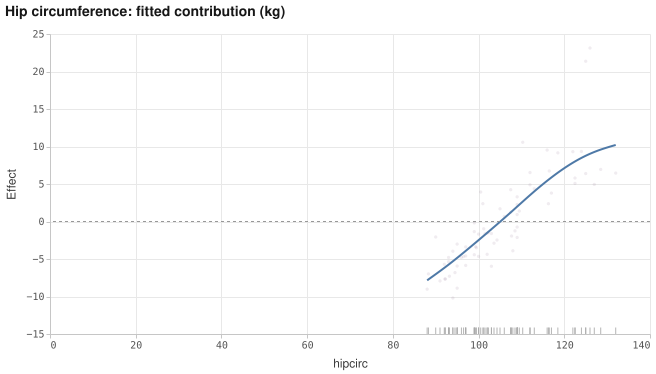

In [3]:
# Each chart is one term's fitted contribution, conditional on the rest.
display(mb.plot.plot_partial_effects(fit, which="waistcirc").properties(
    title="Waist circumference: fitted contribution (kg)",
))
display(mb.plot.plot_partial_effects(fit, which="hipcirc").properties(
    title="Hip circumference: fitted contribution (kg)",
))


Both curves are conditional contributions: the waist curve is what waist
circumference adds given that hip circumference and the other terms are in
the model, and vice versa. Neither curve can be read as the effect of that
measurement on its own. If one term's fitted contribution can be closely reproduced by the other
terms, its allocation to that measurement is difficult to interpret
separately. `concurvity` measures this overlap.


## The concurvity diagnostic: `concurvity()`

`concurvity()` measures how far one smooth term's function space (the set of curves the term can produce) reaches into another's, the additive-model analogue of collinearity
{cite}`wood2017generalized`. Each row of its default table measures one
term against the rest of the model and reports three values from 0 (the
term's space is orthogonal to the others) to 1 (its functions lie in their
span): `worst`, the largest fraction of any term function the rest can
reproduce; `observed`, the same fraction at the fitted coefficients; and
`estimate`, an average over coefficient directions. `worst` is a
pessimistic bound, because rich bases share their low-frequency directions
even between unrelated covariates, so rows are read against each other and
pairs are ranked by `observed`. Each term is first centred to zero mean, which removes the constant
direction from its functions.


In [4]:
from bench_tables import table

concurvity_rows = fit.concurvity(output="records")
summary = pl.DataFrame(concurvity_rows).sort("worst", descending=True)
by_term = {row["term"]: row for row in concurvity_rows}
table(
    summary, stub="term", stubhead="Term", decimals=2,
    title="Concurvity of each term against the rest of the model",
    subtitle="0 (orthogonal) to 1 (reproducible by the other terms); 71 women",
    better={"worst": "max"},
    notes=(
        "worst: the largest fraction of any term function the rest of the "
        "model can reproduce; observed: that fraction at the fitted "
        "coefficients; estimate: averaged over coefficient directions.",
        "Bold marks the term most reproducible by the rest.",
    ),
)


GT(_tbl_data=shape: (4, 4)
┌────────────────┬──────────┬──────────┬──────────┐
│ term           ┆ worst    ┆ observed ┆ estimate │
│ ---            ┆ ---      ┆ ---      ┆ ---      │
│ str            ┆ f64      ┆ f64      ┆ f64      │
╞════════════════╪══════════╪══════════╪══════════╡
│ bbs(waistcirc) ┆ 0.946884 ┆ 0.908787 ┆ 0.635875 │
│ bbs(anthro3c)  ┆ 0.92107  ┆ 0.835943 ┆ 0.615293 │
│ bbs(hipcirc)   ┆ 0.893749 ┆ 0.850683 ┆ 0.649898 │
│ bbs(age)       ┆ 0.870896 ┆ 0.485709 ┆ 0.466629 │
└────────────────┴──────────┴──────────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x10ea151f0>, _boxhead=Boxhead([ColInfo(var='term', type=<ColInfoTypeEnum.stub: 2>, column_label='term', column_align='left', column_width=None), ColInfo(var='worst', type=<ColInfoTypeEnum.default: 1>, column_label='worst', column_align='right', column_width=None), ColInfo(var='observed', type=<ColInfoTypeEnum.default: 1>, column_label='observed', column_align='right', column_width=None), ColInfo(var='estimate', type=<ColInfoTypeEnum.default: 1>, column_label='estimate', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x1126d3590>, _spanners=Spanners([]), _heading=Heading(title='Concurvity of each term against the rest of the model', subtitle='0 (orthogonal) to 1 (reproducible by the other terms); 71 women', preheader=None), _stubhead='Term', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x11303e330>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x1127fbec0>, _source_notes=['worst: the largest fraction of any term function the rest of the model can reproduce; observed: that fraction at the fitted coefficients; estimate: averaged over coefficient directions.', 'Bold marks the term most reproducible by the rest.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x1126cc860>, _formats=[<great_tables._gt_data.FormatInfo object at 0x1130b6cc0>, <great_tables._gt_data.FormatInfo object at 0x113084290>, <great_tables._gt_data.FormatInfo object at 0x11269f620>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x11269f110>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='t

The two girth terms have the highest values. Waist circumference's functions can be
reproduced by the rest of the model to a worst-case fraction of
{eval}`f"{by_term['bbs(waistcirc)']['worst']:.2f}"`, and the fitted waist
curve to {eval}`f"{by_term['bbs(waistcirc)']['observed']:.2f}"` of its
squared length; hip circumference's fractions are
{eval}`f"{by_term['bbs(hipcirc)']['worst']:.2f}"` and
{eval}`f"{by_term['bbs(hipcirc)']['observed']:.2f}"`. Age, whose values
the girth measurements do not track, is lower on both measures. The
default table pools every other term into the rest, so it does not say
which term does the reproducing; the pairwise form does.


In [5]:
pairs = pl.DataFrame(fit.concurvity(pairwise=True, output="records")).sort(
    "worst", descending=True)
# The most concurved ordered pair, quoted in the reading below.
top_pair_worst = pairs["worst"][0]
table(
    pairs, stub="term", stubhead="Term", decimals=2,
    title="Pairwise concurvity: each term measured against one other",
    subtitle="0 (orthogonal) to 1 (reproducible); mgcv's full = FALSE measures, 71 women",
    better={"worst": "max"},
    notes=(
        "Each row measures term against against alone: worst is the largest "
        "fraction of any term function that against can reproduce; observed "
        "is that fraction at the fitted coefficients. No intercept is "
        "involved and the diagonal is omitted.",
        "Bold marks the most concurved ordered pair.",
    ),
)


GT(_tbl_data=shape: (12, 5)
┌────────────────┬────────────────┬──────────┬──────────┬──────────┐
│ term           ┆ against        ┆ worst    ┆ observed ┆ estimate │
│ ---            ┆ ---            ┆ ---      ┆ ---      ┆ ---      │
│ str            ┆ str            ┆ f64      ┆ f64      ┆ f64      │
╞════════════════╪════════════════╪══════════╪══════════╪══════════╡
│ bbs(waistcirc) ┆ bbs(hipcirc)   ┆ 0.828848 ┆ 0.797775 ┆ 0.386545 │
│ bbs(hipcirc)   ┆ bbs(waistcirc) ┆ 0.828848 ┆ 0.783196 ┆ 0.427713 │
│ bbs(anthro3c)  ┆ bbs(waistcirc) ┆ 0.718524 ┆ 0.673181 ┆ 0.322904 │
│ bbs(waistcirc) ┆ bbs(anthro3c)  ┆ 0.718524 ┆ 0.633751 ┆ 0.268735 │
│ bbs(hipcirc)   ┆ bbs(anthro3c)  ┆ 0.689666 ┆ 0.562747 ┆ 0.261953 │
│ …              ┆ …              ┆ …        ┆ …        ┆ …        │
│ bbs(anthro3c)  ┆ bbs(age)       ┆ 0.652795 ┆ 0.192102 ┆ 0.20644  │
│ bbs(hipcirc)   ┆ bbs(age)       ┆ 0.644935 ┆ 0.157596 ┆ 0.182002 │
│ bbs(age)       ┆ bbs(hipcirc)   ┆ 0.644935 ┆ 0.176635 ┆ 0.143126 │
│ bbs(age)       ┆ bbs(waistcirc) ┆ 0.509154 ┆ 0.234622 ┆ 0.168458 │
│ bbs(waistcirc) ┆ bbs(age)       ┆ 0.509154 ┆ 0.210882 ┆ 0.192671 │
└────────────────┴────────────────┴──────────┴──────────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x11269ecc0>, _boxhead=Boxhead([ColInfo(var='term', type=<ColInfoTypeEnum.stub: 2>, column_label='term', column_align='left', column_width=None), ColInfo(var='against', type=<ColInfoTypeEnum.default: 1>, column_label='against', column_align='left', column_width=None), ColInfo(var='worst', type=<ColInfoTypeEnum.default: 1>, column_label='worst', column_align='right', column_width=None), ColInfo(var='observed', type=<ColInfoTypeEnum.default: 1>, column_label='observed', column_align='right', column_width=None), ColInfo(var='estimate', type=<ColInfoTypeEnum.default: 1>, column_label='estimate', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x1126cd130>, _spanners=Spanners([]), _heading=Heading(title='Pairwise concurvity: each term measured against one other', subtitle="0 (orthogonal) to 1 (reproducible); mgcv's full = FALSE measures, 71 women", preheader=None), _stubhead='Term', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x1126954c0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x113124d70>, _source_notes=['Each row measures term against against alone: worst is the largest fraction of any term function that against can reproduce; observed is that fraction at the fitted coefficients. No intercept is involved and the diagonal is omitted.', 'Bold marks the most concurved ordered pair.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x113124c20>, _formats=[<great_tables._gt_data.FormatInfo object at 0x1126ebfe0>, <great_tables._gt_data.FormatInfo object at 0x113124800>, <great_tables._gt_data.FormatInfo object at 0x113124c80>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x113124a40>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='t

The pairwise table names the pair: waist and hip circumference, at
worst-case {eval}`f"{top_pair_worst:.2f}"` in both
directions, are the most concurved ordered pairs in the model, ahead of
every pair involving the derived index, and the pairs involving age come
last. High pairwise concurvity means the two effects are not separately
identified, because the fit could move information between the two
curves. It does not by itself say whether one term is redundant: that
depends on how much signal sits in the part of each term's space the other
cannot reach, which is a question about prediction, and the next section
measures it.


(the-decision-the-table-supports)=
## Hip-circumference removal

The four-term model is compared with a model omitting hip circumference. Both
models are tuned and scored on the same ten folds, so their fold-by-fold
risk differences can be paired. These scores assess the removal descriptively;
the same folds also selected each model's stopping point.


In [6]:
# Reduced specification: hip circumference removed. The same folds keep
# the fold-by-fold comparison paired with the four-term model.
reduced_formula = (
    "DEXfat ~ bbs(age, knots=8) + bbs(waistcirc, knots=8)"
    " + bbs(anthro3c, knots=8)"
)
reduced_path = mb.gamboost(
    reduced_formula, data=data, family=mb.Gaussian(),
    control=mb.boost_control(mstop=400, nu=0.1),
)
reduced_cv = reduced_path.cvrisk(folds=folds)
comparison = cv.compare_to(reduced_cv)

print(comparison.describe())
pl.DataFrame({
    "fold": np.arange(1, comparison.n_folds + 1),
    "four-term minus three-term risk (kg²)": comparison.differences,
})


10 paired folds, mstop 35 vs 29
  mean risk difference: -5.11302 (favours the first model)
  standard error: 3.21254 corrected, 2.21102 uncorrected
  No calibrated interval: the two models were compared at their own selected optima, so the interval would not cover the tuning bias. The comparison is descriptive.


fold,four-term minus three-term risk (kg²)
i64,f64
1,-14.48244
2,4.427989
3,0.901066
4,-0.095417
5,-9.736465
6,3.020159
7,-6.45642
8,-7.190825
9,-15.364086


Keeping hip circumference lowers the ten-fold risk by
{eval}`f"{-comparison.mean_difference:.2f}"` kg² on average, with a
corrected paired-fold standard error of
{eval}`f"{comparison.se_corrected:.2f}"` kg². The comparison is
descriptive: each model was scored at its own selected stopping point, so
the difference carries tuning noise and no inferential interval is claimed.

Both girth terms are retained because keeping hip circumference lowers the
paired-fold error. High concurvity still limits interpretation: the model
can divide shared predictive information between the waist and hip curves,
and that division depends on which term boosting updates in this sample.


## Predictions from the chosen model

The chosen model predicts mean body fat from a frame containing the same
measurements. The table demonstrates the call on the first three women of
the study; these are fitted observations rather than a new evaluation set.


In [7]:
profiles = data.select("age", "waistcirc", "hipcirc", "anthro3c").head(3)
predictions = fit.predict(newdata=profiles, type="response")
profiles.with_columns(pl.Series("predicted mean DEXfat (kg)", predictions))


age,waistcirc,hipcirc,anthro3c,predicted mean DEXfat (kg)
i64,f64,f64,f64,f64
57,100.0,112.0,4.5,40.301257
65,99.5,116.5,4.48,42.208636
59,96.0,108.5,4.6,38.389304


Each row now has one predicted mean body-fat value in kg. The reusable
workflow is: fit paths for the candidate specifications, tune the stopping
point on fixed folds, read `concurvity` to find which terms share function
space, and let a paired fold comparison, not the concurvity value itself,
decide whether a term leaves the specification. The model's applicability
remains limited to populations and measurement ranges comparable to this
small study.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | reading overlapping girth terms in a body-fat model and deciding whether one leaves the specification |
| **Observed response** | `DEXfat`, body fat measured by DEXA |
| **Estimand** | mean DEXA fat conditional on the offered measurements; the concurvity fractions of the fitted terms; the paired ten-fold risk difference between the four-term and the three-term specification |
| **Units** | fat and effects in kg; risk in kg²; age in years; circumference in cm |
| **Sampling unit** | one woman |
| **Dependence** | women treated as independent; waist and hip circumference and the derived index are correlated measurements |
| **Split / resampling unit** | the woman, for ten-fold cross-validation and the bootstrap resamples of the extensions |
| **Tuning** | `mstop` by ten-fold `cvrisk` on the shared folds, per specification |
| **Uncertainty** | descriptive paired fold differences with a Nadeau–Bengio corrected standard error (a correction for the overlap of training sets across folds); bootstrap resampling for selection stability; no effect intervals are claimed for the concurved pair |
| **Claim type** | predictive comparison and descriptive diagnostics; no causal interpretation |
:::

The next sections are optional extensions.


## Extension: the split between two concurved terms

If the two girth terms are not separately identified, the boosting
algorithm's choice of which one to update should vary from sample to
sample even while their combined use stays stable. The model is refitted on 40 bootstrap samples at the fixed stopping point of the main fit and
record how many updates each girth term received. Holding `mstop` fixed
means the experiment measures the stability of the allocation, not of the
stopping point.


In [8]:
rng = np.random.default_rng(0)
replicates = 40
girth_updates = []
for _ in range(replicates):
    rows = rng.integers(0, n, n)
    refit = mb.gamboost(
        formula, data=data[rows], family=mb.Gaussian(),
        control=mb.boost_control(mstop=cv.optimal_mstop, nu=0.1),
    )
    updates = {r["learner"]: r["updates"]
               for r in refit.selection_counts(output="records")}
    girth_updates.append({
        "waist updates": updates.get("waistcirc", 0),
        "hip updates": updates.get("hipcirc", 0),
    })
split = pl.DataFrame(girth_updates).with_columns(
    (pl.col("waist updates") + pl.col("hip updates")).alias("combined updates"),
)


The spread of the allocations, and whether the two counts move against each
other, are what the resamples decide. The table summarises the 40
allocations; the chart plots one point per resample.


girth updates per resample,minimum,mean,maximum
str,i64,f64,i64
"""waist""",2,7.65,18
"""hip""",6,13.55,23
"""both combined""",16,21.2,30


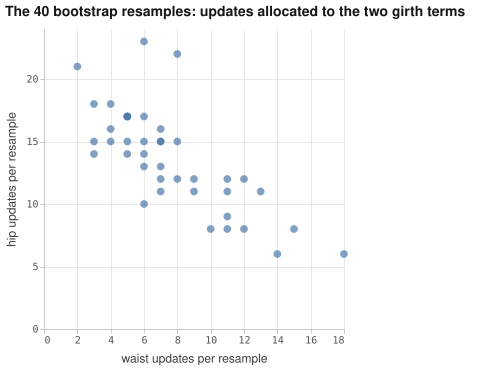

In [9]:
split_summary = pl.DataFrame({
    "girth updates per resample": ["waist", "hip", "both combined"],
    "minimum": [split["waist updates"].min(), split["hip updates"].min(),
                split["combined updates"].min()],
    "mean": [split["waist updates"].mean(), split["hip updates"].mean(),
             split["combined updates"].mean()],
    "maximum": [split["waist updates"].max(), split["hip updates"].max(),
                split["combined updates"].max()],
})
display(split_summary)

# One point per resample: when one girth term takes more updates, the other
# tends to take fewer.
alt.Chart(split).mark_circle(size=60, opacity=0.7).encode(
    x=alt.X("waist updates", title="waist updates per resample"),
    y=alt.Y("hip updates", title="hip updates per resample"),
).properties(title="The 40 bootstrap resamples: updates allocated to the two girth terms")


Across the 40 resamples waist circumference received between
{eval}`split["waist updates"].min()` and
{eval}`split["waist updates"].max()` updates and hip circumference between
{eval}`split["hip updates"].min()` and {eval}`split["hip updates"].max()`,
while their combined total stayed between
{eval}`split["combined updates"].min()` and
{eval}`split["combined updates"].max()`. The chart's downward drift is the
practical form of the non-identifiability the pairwise table reported: a
resample decides how much of the shared girth information each curve
carries, not whether it enters the model. Both terms were selected in
every resample, and the experiment says nothing about their predictive
value, which the paired fold comparison of the main workflow measured.


(extension-what-a-saturated-basis-does-to-the-worst-case-measure)=
## Extension: saturated bases and worst-case concurvity

The main fit held every basis at `knots=8` because four default `bbs`
bases, about 24 columns each, approach the 71 observations. This extension
fits the same formula with default bases and repeats the summary table, to
show what saturation does to the diagnostic.


In [10]:
# Default bases: each term's span is now large relative to the sample.
default_formula = "DEXfat ~ " + " + ".join(
    f"bbs({name})" for name in ["age", "waistcirc", "hipcirc", "anthro3c"]
)
default_fit = mb.gamboost(
    default_formula, data=data, family=mb.Gaussian(),
    control=mb.boost_control(mstop=400, nu=0.1),
)
default_rows = default_fit.concurvity(output="records")
pl.DataFrame(default_rows).sort("worst", descending=True)


term,worst,observed,estimate
str,f64,f64,f64
"""bbs(hipcirc)""",1.0,0.974984,0.906393
"""bbs(age)""",1.0,0.954658,0.921631
"""bbs(waistcirc)""",1.0,0.981609,0.915226
"""bbs(anthro3c)""",1.0,0.996806,0.97397


With the default bases, `worst` reads
{eval}`f"{max(r['worst'] for r in default_rows):.2f}"` for every term:
once the combined span of the terms approaches the whole observation
space, every term's functions are reproducible by the rest in the worst
case, and the measure stops distinguishing the terms. `observed` still
ranks them, but reducing the basis sizes, as in the main fit, makes the worst-case
measure informative for this sample.

Together, the three readings answer three separate questions: the summary and
pairwise tables say how much function space the terms share, the paired
fold comparison says whether the overlap costs prediction, and the
resampling experiment says how the shared space is allocated between the
terms. A specification that keeps a concurved pair can still be the right
predictive choice; its partial effects must then be read as one divided
signal rather than two separate effects.


```{bibliography}
:filter: docname in docnames
```
